In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
class_names = ["setosa", "versicolor", "virginica"]
colors = ["#007F86", "#DB8500", "#7254A3"]


In [2]:
iris = load_iris()
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df = pd.DataFrame(iris.data, columns=features)
df["species"] = pd.Series(iris.target).map({0: "setosa", 1: "versicolor", 2: "virginica"})

print("Dataset shape:", df.shape)
print(df.head().to_string(index=False))


Dataset shape: (150, 5)
 sepal_length  sepal_width  petal_length  petal_width species
          5.1          3.5           1.4          0.2  setosa
          4.9          3.0           1.4          0.2  setosa
          4.7          3.2           1.3          0.2  setosa
          4.6          3.1           1.5          0.2  setosa
          5.0          3.6           1.4          0.2  setosa


In [3]:
df.info()
print("\nMissing values:")
print(df.isna().sum())
print("\nRepeated rows:", df.duplicated().sum())
print("\nFlowers in each species:")
print(df["species"].value_counts().sort_index())
print("\nMeasurement summary:")
print(df[features].describe().round(2).to_string())


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Repeated rows: 1

Flowers in each species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Measurement summary:
       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00 

In [4]:
X = df[features]
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
split_counts = pd.DataFrame({"Training": y_train.value_counts(),"Test": y_test.value_counts()}).reindex(class_names)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print(split_counts.to_string())


Training rows: 120
Test rows: 30
            Training  Test
species                   
setosa            40    10
versicolor        40    10
virginica         40    10


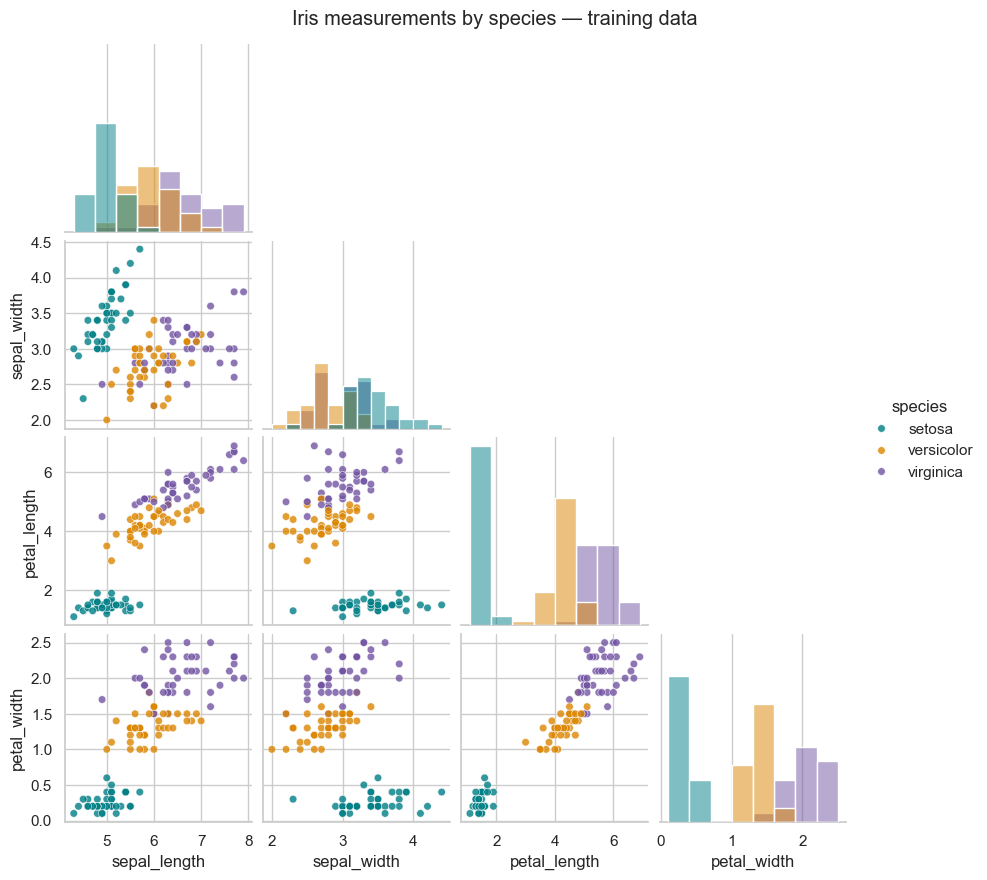

In [5]:
training_data = X_train.copy()
training_data["species"] = y_train

pairplot = sns.pairplot(training_data, vars=features, hue="species", hue_order=class_names,palette=colors, diag_kind="hist", corner=True, height=2.15,plot_kws={"s": 30, "alpha": 0.8})
pairplot.fig.suptitle("Iris measurements by species — training data", y=1.02)
plt.show()


Setosa separates clearly in the petal measurements. Versicolor and
virginica overlap more. This suggests that distinguishing those two
species may be harder.


In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaling_check = pd.DataFrame({"Training mean after scaling": X_train_scaled.mean(axis=0),"Training SD after scaling": X_train_scaled.std(axis=0)}, index=features)
print(scaling_check.round(3).to_string())


              Training mean after scaling  Training SD after scaling
sepal_length                         -0.0                        1.0
sepal_width                           0.0                        1.0
petal_length                          0.0                        1.0
petal_width                           0.0                        1.0


In [7]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled)
print("Logistic Regression training complete.")


Logistic Regression training complete.


In [8]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_scaled, y_train)
tree_predictions = tree_model.predict(X_test_scaled)
print("Decision Tree training complete.")


Decision Tree training complete.


In [9]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, logistic_predictions, labels=class_names, digits=4, zero_division=0))
print("DECISION TREE")
print(classification_report(y_test, tree_predictions, labels=class_names, digits=4, zero_division=0))


LOGISTIC REGRESSION
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

DECISION TREE
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



In [10]:
logistic_report = classification_report(y_test, logistic_predictions, labels=class_names,output_dict=True, zero_division=0)
tree_report = classification_report(y_test, tree_predictions, labels=class_names,output_dict=True, zero_division=0)
comparison = pd.DataFrame({"Model": ["Logistic Regression", "Decision Tree"],"Accuracy": [accuracy_score(y_test, logistic_predictions),accuracy_score(y_test, tree_predictions)],"Precision (macro)": [logistic_report["macro avg"]["precision"],tree_report["macro avg"]["precision"]],"Recall (macro)": [logistic_report["macro avg"]["recall"],tree_report["macro avg"]["recall"]],"F1-score (macro)": [logistic_report["macro avg"]["f1-score"],tree_report["macro avg"]["f1-score"]]})
print(comparison.round(4).to_string(index=False))


              Model  Accuracy  Precision (macro)  Recall (macro)  F1-score (macro)
Logistic Regression    0.9333             0.9333          0.9333            0.9333
      Decision Tree    0.9333             0.9333          0.9333            0.9333


In [11]:
logistic_cm = confusion_matrix(y_test, logistic_predictions, labels=class_names)
tree_cm = confusion_matrix(y_test, tree_predictions, labels=class_names)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, matrix, title in zip(
    axes, [logistic_cm, tree_cm], ["Logistic Regression", "Decision Tree"]):
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,vmin=0, vmax=10, xticklabels=class_names, yticklabels=class_names, ax=a)
ax.set_title(title)
ax.set_xlabel("Predicted species")
ax.set_ylabel("Actual species")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
fig.suptitle("Confusion matrices — 30 test flowers", y=1.02)
plt.tight_layout()
plt.show()


IndentationError: expected an indented block after 'for' statement on line 5 (2359930333.py, line 7)

In [ ]:
test_results = X_test.copy()
test_results["actual_species"] = y_test
test_results["logistic_prediction"] = logistic_predictions
test_results["tree_prediction"] = tree_predictions

mistakes = test_results[(test_results["actual_species"] != test_results["logistic_prediction"]) |(test_results["actual_species"] != test_results["tree_prediction"])]
print(mistakes.to_string())


     sepal_length  sepal_width  petal_length  petal_width actual_species logistic_prediction tree_prediction
134           6.1          2.6           5.6          1.4      virginica          versicolor      versicolor
77            6.7          3.0           5.0          1.7     versicolor           virginica       virginica


In [ ]:
plot_features = ["petal_length", "petal_width"]
X_train_plot = X_train[plot_features]

plot_scaler = StandardScaler()
X_train_plot_scaled = plot_scaler.fit_transform(X_train_plot)

logistic_plot_model = LogisticRegression(max_iter=1000)
logistic_plot_model.fit(X_train_plot_scaled, y_train)

tree_plot_model = DecisionTreeClassifier(random_state=42)
tree_plot_model.fit(X_train_plot_scaled, y_train)


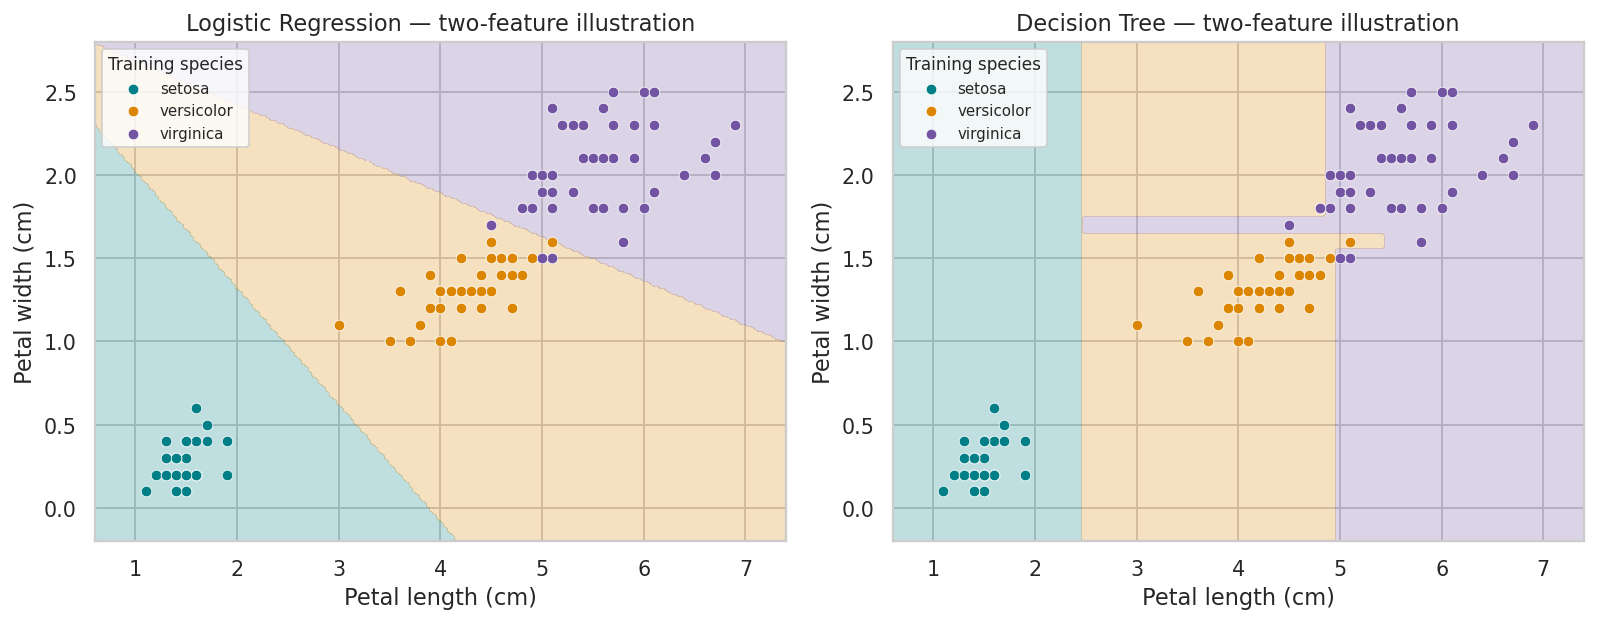

In [ ]:
x_values = np.linspace(X_train_plot["petal_length"].min() - 0.5,X_train_plot["petal_length"].max() + 0.5, 200)
y_values = np.linspace(X_train_plot["petal_width"].min() - 0.3,X_train_plot["petal_width"].max() + 0.3, 200)
xx, yy = np.meshgrid(x_values, y_values)
grid = pd.DataFrame(np.column_stack([xx.ravel(), yy.ravel()]), columns=plot_features)
grid_scaled = plot_scaler.transform(grid)
species_codes = {"setosa": 0, "versicolor": 1, "virginica": 2}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, model, title in zip(
    axes, [logistic_plot_model, tree_plot_model],
    ["Logistic Regression", "Decision Tree"]):
    grid_predictions = model.predict(grid_scaled)
    regions = pd.Series(grid_predictions).map(species_codes).to_numpy()
    regions = regions.reshape(xx.shape)
ax.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.25)
    for species, color in zip(class_names, colors):
rows = y_train == species
ax.scatter( X_train_plot.loc[rows, "petal_length"], X_train_plot.loc[rows, "petal_width"],color=color, label=species, s=32, edgecolors="white", linewidths=0.4)
ax.set_title(title + " — two-feature illustration")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.legend(title="Training species", fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.show()
